# ML 03 — Feature engineering and leakage audit

This notebook transforms the ML_01 table into a modelling table and explicitly connects every engineered feature to the later models. It creates circular wind-direction encodings, relative height variability and a density-squared term, audits leakage and redundancy, and writes `data/processed/feature_engineered_dataset.csv`.

Feature engineering should express plausible geometry/condition information; it does not add new CFD information or restore spatial detail discarded by aggregation.

In [1]:
from pathlib import Path
import os

# Works whether Jupyter starts in the repository root or this notebook's folder.
_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in _candidates if (p / "data" / "raw").exists() and (p / "Machine Learning Pipeline").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Could not find the repository root. Open this notebook from inside the T006 project folder.")
DATA_RAW = ROOT / "data" / "raw"
DATA_PROCESSED = ROOT / "data" / "processed"
RESULTS = ROOT / "results"
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

processed_path = DATA_PROCESSED / "layout_level_dataset.csv"
if not processed_path.exists():
    raise FileNotFoundError("Run ML_01_dataset_understanding_data_dictionary.ipynb first; it builds this processed dataset from raw data.")
df = pd.read_csv(processed_path)
TARGET = "target_U_canopy_mean_m_s"
NUMERIC_FEATURES = ["plan_area_density", "plan_area_density_sq", "height_std_m", "height_max_m", "height_min_m", "height_range_m", "height_skew", "frac_taller_than_mean", "wind_direction_deg"]
CATEGORICAL_FEATURES = ["configuration", "horizontal_configuration", "density_class"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
BASELINE_NUMERIC = ["plan_area_density", "height_mean_m", "height_std_m", "height_max_m", "wind_direction_deg", "building_count"]
BASELINE_FEATURES = BASELINE_NUMERIC + CATEGORICAL_FEATURES
print("Dataset shape:", df.shape)
print("Target:", TARGET)

Dataset shape: (224, 19)
Target: target_U_canopy_mean_m_s


## 1. Engineer features with physical and statistical rationale

- `plan_area_density_sq`: allows a simple nonlinear density response in linear models.
- `wind_direction_sin` and `wind_direction_cos`: encode a circular variable without an artificial discontinuity at 0°/360°.
- `height_coefficient_variation`: relative height spread (`height_std_m / height_mean_m`), with safe handling of a zero mean.

The original angle remains in the table for traceability but is not used as a numeric predictor in the primary model, because raw degrees impose an ordinary linear distance.

In [3]:
engineered = df.copy()
engineered["plan_area_density_sq"] = engineered["plan_area_density"] ** 2
angle_rad = np.deg2rad(engineered["wind_direction_deg"].astype(float))
engineered["wind_direction_sin"] = np.sin(angle_rad)
engineered["wind_direction_cos"] = np.cos(angle_rad)
engineered["height_coefficient_variation"] = np.where(
    engineered["height_mean_m"] != 0,
    engineered["height_std_m"] / engineered["height_mean_m"],
    0.0,
)
assert np.allclose(engineered["plan_area_density_sq"], engineered["plan_area_density"] ** 2)
assert np.allclose(engineered["wind_direction_sin"] ** 2 + engineered["wind_direction_cos"] ** 2, 1.0)
assert engineered["simulation_id"].is_unique and engineered[TARGET].notna().all()
print("Rows:", len(engineered), "| original columns:", len(df.columns), "| engineered columns:", len(engineered.columns))
display(engineered[["simulation_id", "plan_area_density", "plan_area_density_sq", "wind_direction_deg", "wind_direction_sin", "wind_direction_cos", "height_mean_m", "height_std_m", "height_coefficient_variation"]].head())

Rows: 224 | original columns: 19 | engineered columns: 22


,simulation_id,plan_area_density,plan_area_density_sq,wind_direction_deg,wind_direction_sin,wind_direction_cos,height_mean_m,height_std_m,height_coefficient_variation
0,UA0625_d00,0.062500,0.003906,0.0,0.000000,1.000000,16.0,0.0,0.0
1,UA0625_d45,0.062500,0.003906,45.0,0.707107,0.707107,16.0,0.0,0.0
2,UA1111_d00,0.111111,0.012346,0.0,0.000000,1.000000,16.0,0.0,0.0
3,UA1111_d45,0.111111,0.012346,45.0,0.707107,0.707107,16.0,0.0,0.0
4,UA16_d00,0.160000,0.025600,0.0,0.000000,1.000000,16.0,0.0,0.0


## 2. Explicit predictor whitelist and leakage checks

IDs identify rows, the target is the answer, and family/layout identifiers are used only to construct held-out groups. The original catalogue label is retained for auditing but excluded because it may duplicate information already encoded by the layout-derived configuration. `height_mean_m` and `building_count` are retained in the dataset but omitted from the engineered feature set to keep the feature definition explicit; they are included in a separate baseline ablation where stated.

In [4]:
NUMERIC_FEATURES = [
    "plan_area_density", "plan_area_density_sq", "height_std_m", "height_max_m",
    "height_min_m", "height_range_m", "height_skew", "frac_taller_than_mean",
    "wind_direction_sin", "wind_direction_cos", "height_coefficient_variation",
]
CATEGORICAL_FEATURES = ["configuration", "horizontal_configuration", "density_class"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
BASELINE_NUMERIC = ["plan_area_density", "height_std_m", "height_max_m", "building_count", "wind_direction_sin", "wind_direction_cos"]
BASELINE_FEATURES = BASELINE_NUMERIC + CATEGORICAL_FEATURES
forbidden_predictors = {TARGET, "simulation_id", "layout_id", "family_id", "configuration_metadata_label", "wind_direction_deg"}
assert not (set(FEATURES) & forbidden_predictors)
missing_columns = sorted(set(FEATURES + BASELINE_FEATURES) - set(engineered.columns))
assert not missing_columns, f"Missing model features: {missing_columns}"
print("Primary engineered predictors:")
for feature in FEATURES: print(" -", feature)
print("\nBaseline predictors for ablation:")
for feature in BASELINE_FEATURES: print(" -", feature)
print("\nExcluded from predictors:")
for feature in sorted(forbidden_predictors): print(" -", feature)
print("\nThe family/layout identifiers are used for splitting only, never as predictors.")

Primary engineered predictors:
 - plan_area_density
 - plan_area_density_sq
 - height_std_m
 - height_max_m
 - height_min_m
 - height_range_m
 - height_skew
 - frac_taller_than_mean
 - wind_direction_sin
 - wind_direction_cos
 - height_coefficient_variation
 - configuration
 - horizontal_configuration
 - density_class

Baseline predictors for ablation:
 - plan_area_density
 - height_std_m
 - height_max_m
 - building_count
 - wind_direction_sin
 - wind_direction_cos
 - configuration
 - horizontal_configuration
 - density_class

Excluded from predictors:
 - configuration_metadata_label
 - family_id
 - layout_id
 - simulation_id
 - target_U_canopy_mean_m_s
 - wind_direction_deg

The family/layout identifiers are used for splitting only, never as predictors.


## 3. Correlation, redundancy and categorical audit

A correlation matrix helps flag redundant numeric columns. It is not a feature-selection algorithm and does not capture all nonlinear dependencies. The square-density term is expected to correlate with density by construction; this is acceptable as an explicit nonlinear term for Ridge, but tree models may not need it. Feature ablation in ML_07 tests whether the engineered set helps rather than assuming that more features are always better.

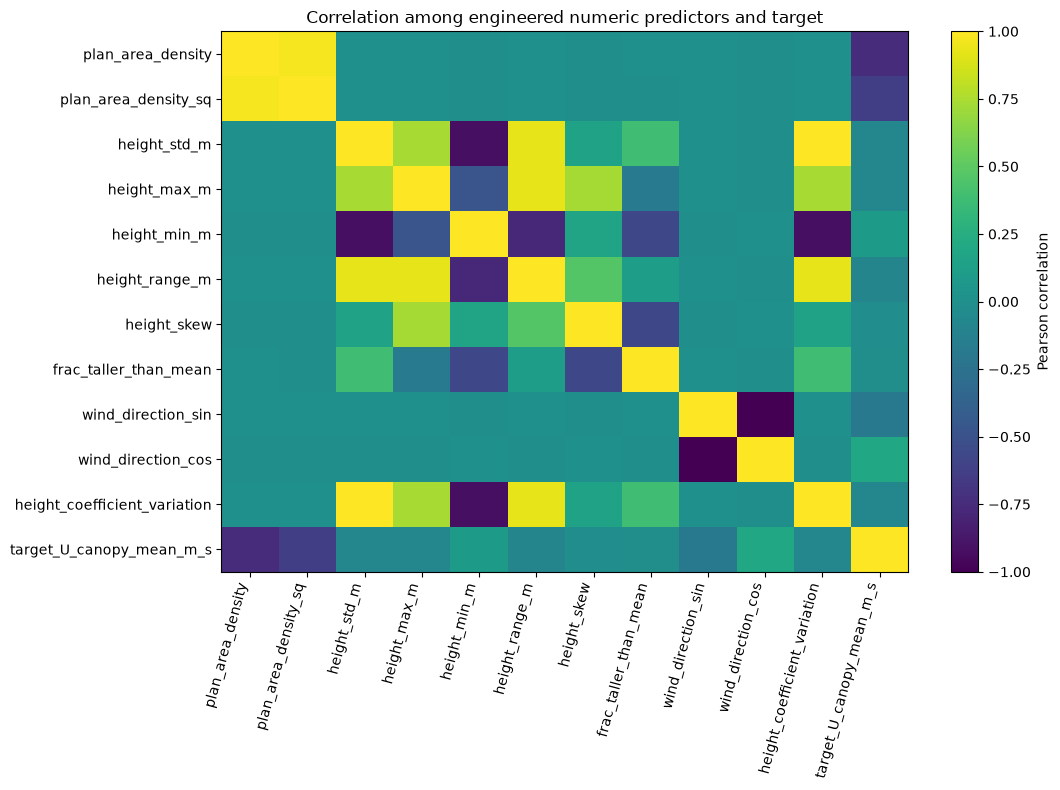

Numeric feature pairs with |correlation| ≥ 0.90 (review, do not delete automatically):


,feature_1,feature_2,abs_correlation
0,plan_area_density,plan_area_density_sq,0.975
1,height_std_m,height_min_m,0.914
2,height_std_m,height_range_m,0.925
3,height_std_m,height_coefficient_variation,1.000
4,height_max_m,height_range_m,0.927
5,height_min_m,height_coefficient_variation,0.914
6,height_range_m,height_coefficient_variation,0.925
7,wind_direction_sin,wind_direction_cos,1.000



Levels of configuration:


,count
configuration,
idealized-CL,64
idealized-HR,64
idealized-SM,64
idealized-uniform,32



Levels of horizontal_configuration:


,count
horizontal_configuration,
Aligned,112
Staggered,112



Levels of density_class:


,count
density_class,
sparse,84
dense,84
medium,56


In [5]:
corr_cols = [c for c in NUMERIC_FEATURES + [TARGET] if c in engineered.columns]
corr = engineered[corr_cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(11, 8))
image = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=75, ha="right")
ax.set_yticks(range(len(corr.index)), corr.index)
ax.set_title("Correlation among engineered numeric predictors and target")
fig.colorbar(image, ax=ax, label="Pearson correlation")
plt.tight_layout(); plt.show()

abs_corr = corr.abs()
redundant_pairs = []
for i, first in enumerate(abs_corr.columns):
    for j in range(i + 1, len(abs_corr.columns)):
        second = abs_corr.columns[j]
        value = abs_corr.iloc[i, j]
        if value >= 0.90:
            redundant_pairs.append({"feature_1": first, "feature_2": second, "abs_correlation": value})
print("Numeric feature pairs with |correlation| ≥ 0.90 (review, do not delete automatically):")
display(pd.DataFrame(redundant_pairs).round(3) if redundant_pairs else pd.DataFrame(columns=["feature_1", "feature_2", "abs_correlation"]))
for col in CATEGORICAL_FEATURES:
    print(f"\nLevels of {col}:")
    display(engineered[col].value_counts(dropna=False).rename("count").to_frame())

## 4. Save the modelling table

The engineered table preserves all original columns and appends the derived features. Later notebooks load this exact artifact and use the whitelist above. Re-run this notebook whenever ML_01 regenerates the base table.

In [6]:
modeling_path = DATA_PROCESSED / "feature_engineered_dataset.csv"
engineered.to_csv(modeling_path, index=False)
print("Created:", modeling_path)
print("Rows:", len(engineered), "| columns:", len(engineered.columns))
print("Primary feature count:", len(FEATURES), "| baseline feature count:", len(BASELINE_FEATURES))
print("The saved dataset includes engineered features; model inputs are controlled by the explicit whitelist in each modelling notebook.")

# A separate schema dictionary documents the additional derived columns without changing ML_01's dictionary.
base_dictionary_path = DATA_PROCESSED / "data_dictionary.csv"
base_dictionary = pd.read_csv(base_dictionary_path) if base_dictionary_path.exists() else pd.DataFrame(columns=["field", "units", "type", "meaning", "source", "model_use"])
extra_definitions = {
    "wind_direction_sin": ("unitless", "float", "Sine encoding of wind direction in radians", "derived from wind_direction_deg", "numeric predictor"),
    "wind_direction_cos": ("unitless", "float", "Cosine encoding of wind direction in radians", "derived from wind_direction_deg", "numeric predictor"),
    "height_coefficient_variation": ("unitless", "float", "Height standard deviation divided by mean height; zero used if mean height is zero", "derived from height_std_m / height_mean_m", "numeric predictor"),
}
extra_rows = []
for column in engineered.columns:
    if column not in set(base_dictionary.get("field", [])):
        units, field_type, meaning, source, model_use = extra_definitions.get(
            column, ("see base dictionary", str(engineered[column].dtype), "Engineered/retained field in the modelling table", "derived or retained from the ML_01 table", "not used unless listed in predictor whitelist")
        )
        extra_rows.append({"field": column, "units": units, "type": field_type, "meaning": meaning, "source": source, "model_use": model_use})
engineered_dictionary = pd.concat([base_dictionary, pd.DataFrame(extra_rows)], ignore_index=True)
engineered_dictionary_path = DATA_PROCESSED / "feature_engineered_data_dictionary.csv"
engineered_dictionary.to_csv(engineered_dictionary_path, index=False)
print("Created matching engineered-data dictionary:", engineered_dictionary_path)
assert engineered_dictionary["field"].tolist() == engineered.columns.tolist(), "The engineered data dictionary must match the engineered table columns and order."


Created: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/data/processed/feature_engineered_dataset.csv
Rows: 224 | columns: 22
Primary feature count: 14 | baseline feature count: 9
The saved dataset includes engineered features; model inputs are controlled by the explicit whitelist in each modelling notebook.
Created matching engineered-data dictionary: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/data/processed/feature_engineered_data_dictionary.csv
